# Introducción
En esta TS5 aprendimos sobre la utilización de algún periodograma como estimador de la densidad espectral de potencia, además del significado práctico y teórico del ancho de banda de una señal.

En este caso elegimos trabajar con el periodograma de Welch, una técnica la cuál utiliza el ventaneo explícito con una ventana a elección para reducir la varianza del estimador. Además fracciona el vector con el contenido de la señal, de tamaño N, vectores de tamaño L, solapados entre sí L/2. Luego aplica el periodograma sobre cada uno de los vectores para, posteriormente, promediarlos.

Por otro lado, el ancho de banda es el rango de frecuencias que ocupa una señal. Visto desde el punto de vista de la PSD, esto significa que son las frecuencias donde se encuentra concentrada la mayor parte de la potencia de la señal.

Si bien teóricamente esto es sencillo, hay que proponer que significa la mayor parte de la potencia. Muchas veces se usa el criterio de que lo que este por arriba de -3dB con relación a la potencia máxima es parte del ancho de banda, pues en una diferencia de -3dB se encuentra la mitad de la potencia máxima. Sin embargo, en muchas de las señales estudiadas, existe una fuerte componente de continua debida a ruido, lo cuál haría que este criterio de -3dB pueda dejar afuera algunas componentes.

Por esto decidimos utilizar el termino de ancho de banda como el rango de potencias donde se acumula el 99% de la potencia de la señal (según los estandares usuales se puede tomar entre el 95% y 99%). Para que este ancho no vaya siempre desde los 0 Hz hasta algún valor de frecuencia, es decir que siempre sea un pasa bajos, decidimos también que este rango no sea del 0% al 99% de la energía, si no que consideramos el ancho de banda como la franja donde se acumula la potencia desde el 0.5% hasta el 99.5% de la misma.

# Resolución
Cómo en cada tarea semanal, arrancamos importando nuestras librerías. En este caso aunque incluimos scipy.fft como en ocasiones anteriores, lo usaremos únicamente para un análisis al final ya que no se volverá a utilizar la fft, si no que la reemplazamos con sig.welch, es decir, el periodograma de Welch.

In [1]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq   
import scipy.io as sio

Ahora, definimos dos funciones que utilizaremos a lo largo del análisis de todas las señales. La primera la utilizaremos para realizar el periodograma de Welch. En la misma tendremos como parámetros la señal, su frecuencia de muestreo y el vector L, el cuál contendrá distintos valores de longitud en base a distintos K que previamente definiremos. Esto último, con el propósito de buscar un K que nos parezca que su sesgo y su varianza sean lo suficientemente buenos para realizar el análisis. 

Podemos ver como en sig.welch aparece el parámetro detrend=False. Esto lo hacemos debido a que por default este valor esta seteado en constant, lo que hace que el periodograma elimine la media de la data. Esto es útil en ciertas aplicaciones, como lo veremos en el caso del ancho de banda, pero en esta función utilizamos el periodograma para comparar su potencia con el de la señal original, y si eliminamos la media claramente estos valores no serán iguales.

Como último detalle de esta función, podemos ver como calculamos la potencia de la señal y de la densidad espectral de potencia de la siguiente manera:
\begin{equation}
P_x = \frac{1}{N}\sum_{n=0}^{N-1}|x_{[n]}|^2
\end{equation}
\begin{equation}
P_\widehat{S_x} = \Delta_f\sum_{n=0}^{N-1}\widehat{S_x}
\end{equation}
Donde la densidad espectral de potencia la multiplicamos por la resolución espectral debido a que, justamente, es una densidad de potencia y hay que convertirlo en un valor de potencia.

In [2]:
def perio_welch_hann(signal, fs, L):
    N = len(signal)
    signal = signal.astype(np.float64)
    potx = np.mean(signal**2)
    for l in L:
        freq, PSD = sig.welch(signal,fs,"hann",l,detrend=False)
        res = freq[1] - freq[0]
        pot_welch = np.sum(PSD) * res
        sesgo = 100 * (pot_welch - potx)/potx
        print(f"K={N//l}, Potencia={pot_welch:.2g}, sesgo (%)={sesgo:.4f}%")

Como un mínimo detalle, nuestra definición de sesgo en la función anterior no es del todo correcto. Primero el sesgo lo expresamos como un valor porcentual, lo cuál no es el sesgo si no el error relativo porcentual, pero nos da una idea más visual de que tanto se diferencia la potencia de la señal con la potencia del periodograma.

Continuamos con la función band_width, la cuál funciona como explicamos en la introducción. Calculamos la suma acumulativa de la potencia del PSD mediante la función cumsum y multiplicando nuevamente por $\Delta_f$. Esto nos permitirá conocer la potencia acumulada a cada valor de frecuencia del espectro. Luego utilizamos la función np.searchsorted, la cuál permite encontrar el índice de un vector donde deberías agregar un valor para no romper su ordenamiento de menor a mayor. Claramente al ser una sumatoria de potencias, el vector potencia está ordenado de menor a mayor por lo cuál searchsorted nos devolverá en que indice se encuentra la potencia acumulada de 0.5% y 0.995% de la total. El potencia[-1] significa que tomará el ultimo valor del vector potencia, que al ser una suma acumulativa debería ser el total de la potencia. Por último definimos el ancho de banda como la diferencia entra la frecuencia superior e inferior de la banda.

In [3]:
def band_width(PSD, freq):
    res = freq[1] - freq[0]
    potencia = np.cumsum(PSD) * res
    indice_low = np.searchsorted(potencia, 0.005 * potencia[-1])
    freq_low = freq[indice_low]
    indice_up = np.searchsorted(potencia, 0.995 * potencia[-1])
    freq_up = freq[indice_up]
    BW = freq_up - freq_low
    print(f"frecuencia inferior:{freq_low} Hz, Frecuencia Superior: {freq_up}, Ancho de banda: {BW}")
    return freq_low, freq_up

## Análisis ECG con ruido

La primer señal que analizaremos es un electrocardiograma con ruido. Un electrocardiograma es un estudio médico que tiene como finalidad registrar la actividad eléctrica del corazón en cada latido. Un ciclo del mismo en condiciones normales cuenta con una onda P, el complejos QRS y otra onda T, seguidos por una linea continua antes de repetir el ciclo. Como primer paso, debemos leer los datos de la misma. Además debemos usar la función squeeze, dado que al leer los datos de la matriz queda una dimensión extra vacía que impedía el correcto funcionamiento de funciones posteriores.

In [4]:
fs_ecg = 1000

sio.whosmat('files/ECG_TP4.mat')
mat_struct = sio.loadmat('./files/ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead']
ecg_one_lead = ecg_one_lead.squeeze()

Posteriormente, graficamos la señal en un par de periodos para poder apreciar la forma que tiene.

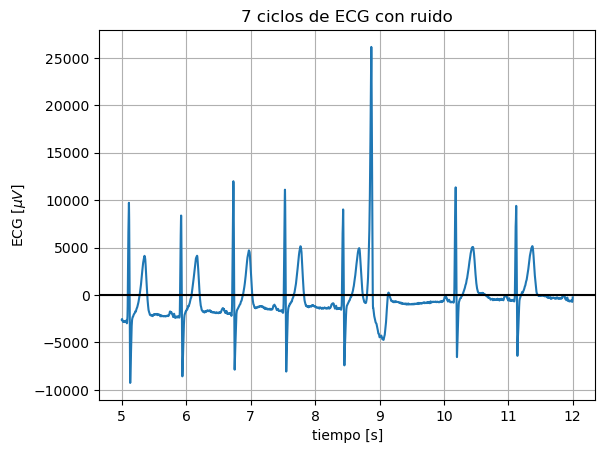

In [5]:
N = len(ecg_one_lead)
t = np.arange(N)/fs_ecg

plt.figure(0)
plt.plot(t[5000:12000],ecg_one_lead[5000:12000])
plt.grid()
plt.title("7 ciclos de ECG con ruido")
plt.xlabel("tiempo [s]")
plt.ylabel("ECG [$\mu V$]")
plt.axhline(0,color="black")

Podemos apreciar un ECG el cuál no es del todo regular, con un pico muy fuerte al rededor de los 9 segundos y que no se encuentra con un piso de 0V, esto último muy probablemente causado por el ruido.

Pasamos a calcular el periodograma, donde utilizaremos como K valores entre 25 y 40 porque nos parecieron valores adecuados para no achicar mucho el vector y tener varias muestras para promediar.

In [6]:
K = np.arange(25, 40, 2)
L = N // K

perio_welch_hann(ecg_one_lead,fs_ecg,L)

K=25, Potencia=2.4e+07, sesgo (%)=-1.8521%
K=27, Potencia=2.6e+07, sesgo (%)=7.2282%
K=29, Potencia=2.4e+07, sesgo (%)=-0.3168%
K=31, Potencia=2.4e+07, sesgo (%)=-0.2329%
K=33, Potencia=2.5e+07, sesgo (%)=3.5669%
K=35, Potencia=2.3e+07, sesgo (%)=-6.5066%
K=37, Potencia=2.5e+07, sesgo (%)=4.8041%
K=39, Potencia=2.4e+07, sesgo (%)=-0.2485%


Los valores de potencia printeados estarán en pW, por lo cuál podemos decir que la señal cuenta con una potencia aproximada por el estimador de 25 $\mu$W. 

Ahora procedemos a ver que pasa con el ancho de banda, para eso si dejaremos el detrend default de la función welch porque nos conviene que el valor de continua no nos modifique el resultado. Además tomaremos un único valor de K en función al paso anterior, eligiendo un valor que tenga una buena relación entre el sesgo y la varianza.

In [7]:
K=39
L = N//K
freq, PSD = sig.welch(ecg_one_lead,fs_ecg,"hann",L)

freq_low, freq_up = band_width(PSD,freq)

frecuencia inferior:0.0 Hz, Frecuencia Superior: 31.50150253877241, Ancho de banda: 31.50150253877241


Si bien en los estudios médicos estándar se utiliza un ancho de banda de 0.05 Hz a 150 Hz, este no es el ancho de la señal si no el ancho de los instrumentos del estudio. Se considera que el 90% de la energía se encuentra por debajo de los 35 Hz, por lo cuál podemos asumir que nuestro resultado de 31.5 Hz es lógico, aunque quizás un poco ajustado considerando que lo definimos como un 99% de la energía.

Pasaremos a graficar la PSD, donde agregaremos además lineas verticales a la altura de las frecuencias superiores e inferiores para poder apreciar el ancho de banda, además de un segundo gráfico donde veremos esta zona con zoom.

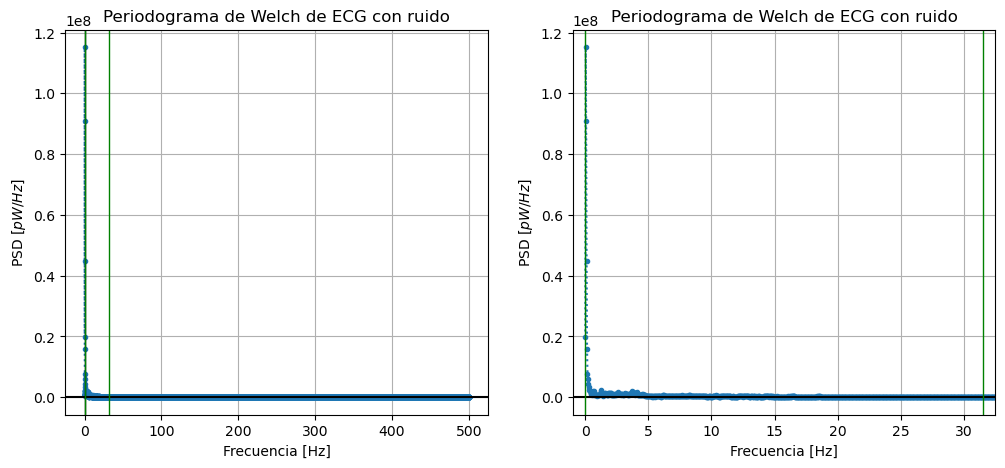

In [8]:
plt.figure(1, figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(freq,PSD,":.")
plt.grid()
plt.title("Periodograma de Welch de ECG con ruido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$pW/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

plt.subplot(1, 2, 2)
plt.plot(freq,PSD,":.")
plt.xlim([freq_low-1,freq_up+1])
plt.grid()
plt.title("Periodograma de Welch de ECG con ruido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$pW/Hz$]")
plt.axhline(0,color="black")
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

Lo que podemos ver en este caso es como casi toda la potencia esta acumulada en valores cercanos al 0 Hz. Esto puede estar indicandonos que la componente de ruido es muy fuerte y esta tapando a las frecuencias reales de la señal. Para poder entender bien que es lo que estamos viendo, repetimos el análisis pero esta vez sin ruido.

## Análisis ECG sin ruido

Comenzamos repitiendo lo del caso anterior, leemos los datos del archivo y graficamos algunos ciclos de la señal.

In [9]:
fs_ecg = 1000

ecg_one_lead = np.load('files/ecg_sin_ruido.npy')
ecg_one_lead = ecg_one_lead.squeeze()

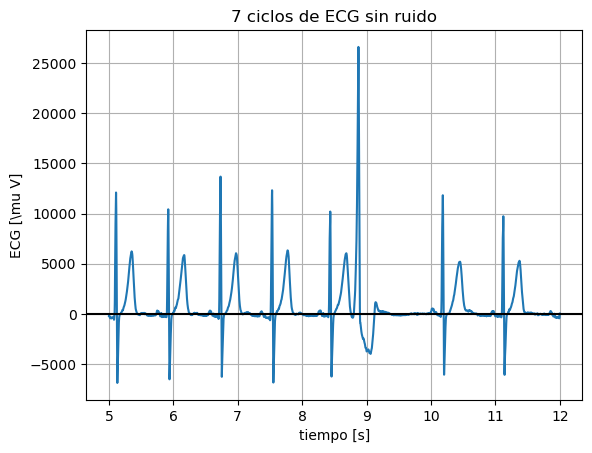

In [10]:
N = len(ecg_one_lead)
t = np.arange(N)/fs_ecg

plt.figure(2)

plt.plot(t[5000:12000],ecg_one_lead[5000:12000])
plt.grid()
plt.title("7 ciclos de ECG sin ruido")
plt.xlabel("tiempo [s]")
plt.ylabel("ECG [\mu V]")
plt.axhline(0,color="black")

Podemos ver que si bien ese pico un poco antes de los 9 segundos se sigue manteniendo, al menos ahora las variaciones se realizan al rededor del cero lo cuál nos da una idea de la eliminación del ruido. Nuevamente realizamos la estimación de la densidad espectral de potencia.

In [11]:
K = np.arange(25, 40, 2)
L = N // K

perio_welch_hann(ecg_one_lead,fs_ecg,L)

K=25, Potencia=7.6e+06, sesgo (%)=0.7910%
K=27, Potencia=8.3e+06, sesgo (%)=10.0203%
K=29, Potencia=7.7e+06, sesgo (%)=2.0860%
K=31, Potencia=8.2e+06, sesgo (%)=9.0382%
K=33, Potencia=7.4e+06, sesgo (%)=-1.8998%
K=35, Potencia=7.4e+06, sesgo (%)=-1.0190%
K=37, Potencia=7.5e+06, sesgo (%)=-0.5770%
K=39, Potencia=7.6e+06, sesgo (%)=1.5567%


Eliminando el ruido nos encontramos con una potencia estimada de aproximadamente 7.5 $\mu$W, lo cuál es lógicamente menor al caso anterior debido a que ya no tendremos la potencia añadida por el ruido. Que esta diferencia sea tan grande comprueba que probablemente el periodograma del caso anterior no podíamos identificar los tonos de la señal debido a que el valor de continua del ruido lo tapaba.

Continuamos realizando la estimación del ancho de banda.

In [12]:
K=37
L = N//K
freq, PSD = sig.welch(ecg_one_lead,fs_ecg,"hann",L)

freq_low, freq_up = band_width(PSD,freq)

frecuencia inferior:0.0 Hz, Frecuencia Superior: 35.80246913580247, Ancho de banda: 35.80246913580247


Este resultado es aún mejor que el anterior, ya que como dijimos se estima que el 90% de la energía de un electrocardiograma se encuentra por debajo de los 35 Hz, y a nosotros con nuestro criterio del 99% de la potencia nos está dando 35.8 Hz. Comprobamos que esta mejora también se observe en el gráfico.

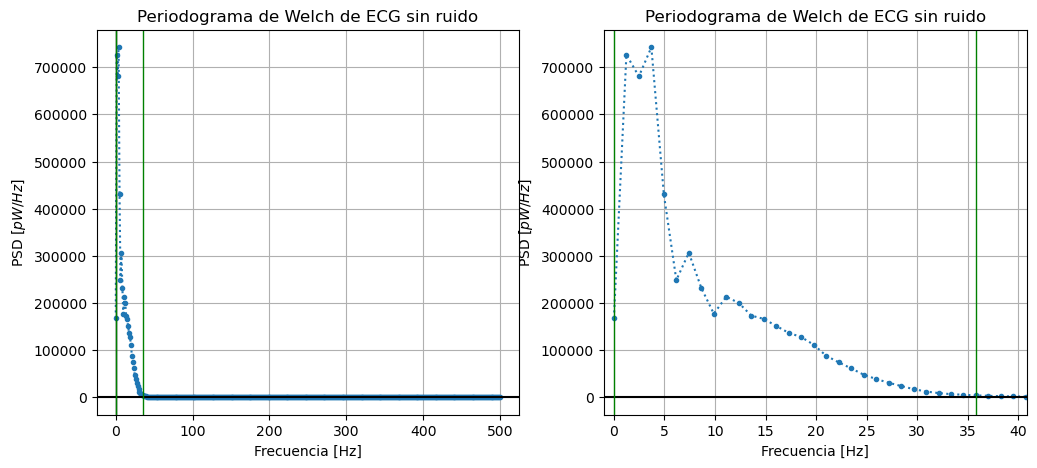

In [13]:
plt.figure(3, figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(freq,PSD,":.")
plt.grid()
plt.title("Periodograma de Welch de ECG sin ruido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$pW/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

plt.subplot(1, 2, 2)
plt.plot(freq,PSD,":.")
plt.xlim([freq_low-1,freq_up+5])
plt.grid()
plt.title("Periodograma de Welch de ECG sin ruido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$pW/Hz$]")
plt.axhline(0,color="black")
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

Ahora efectivamente podemos ver valores de frecuencia distintos de cero. En específico, podemos notar como entre 0 Hz y 5 Hz existen picos elevados, picos mas chicos entre 5 Hz y 10 Hz, y como después de manera casi linea la potencia va decayendo hasta tocar el 0 en los 35 Hz.

## Análisis PPG con ruido

Como segundo tipo de señal nos encontramos con el PPG o fotopletismografía. Este es un método no invasivo para medir la variación del volumen sanguíneo, de los vasos de la piel, mediante un haz de luz. Es utilizado en relojes inteligentes para medir la frecuencia cardíaca y en oxímetros para medir el oxígeno en sangre.

En este primer caso analizamos como se comportará el PSD estimado mediante Welch de una señal de PPG con ruido. Para eso, primero leemos los datos de la señal y la graficamos.

In [14]:
fs_ppg = 400

ppg = np.genfromtxt('files/PPG.csv', delimiter=',', skip_header=1)

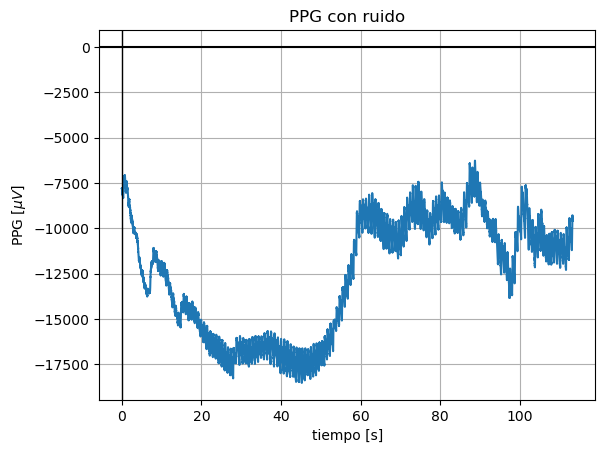

In [15]:
N = len(ppg)
t = np.arange(N)/fs_ppg

plt.figure(4)
plt.plot(t,ppg)
plt.grid()
plt.title("PPG con ruido")
plt.xlabel("tiempo [s]")
plt.ylabel("PPG [$\mu V$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

Nuevamente podemos apreciar un ruido muy fuerte, ya que en condiciones normales un PPG debería tener variaciones alrededor del 0. No solo se encuentra oscilando fuera de ese valor, si no que a distintos tiempos este valor de base parece ser distinto, lo cuál nos habla no solo de un ruido muy fuerte si no que también no uniforme.

In [16]:
K = np.arange(30, 50, 2)
L = N // K

perio_welch_hann(ppg,fs_ppg,L)

K=30, Potencia=1.7e+08, sesgo (%)=0.9395%
K=32, Potencia=1.7e+08, sesgo (%)=0.8495%
K=34, Potencia=1.7e+08, sesgo (%)=0.8205%
K=36, Potencia=1.7e+08, sesgo (%)=0.7889%
K=38, Potencia=1.7e+08, sesgo (%)=0.6996%
K=40, Potencia=1.7e+08, sesgo (%)=0.6837%
K=42, Potencia=1.7e+08, sesgo (%)=0.9718%
K=44, Potencia=1.7e+08, sesgo (%)=0.5312%
K=46, Potencia=1.7e+08, sesgo (%)=0.9292%
K=48, Potencia=1.7e+08, sesgo (%)=0.5433%


En este caso nos encontramos frente a una potencia estimada de 170$\mu$W. Ahora vemos que sucede con su ancho de banda.

In [17]:
K=44
L = N//K

freq, PSD = sig.welch(ppg,fs_ppg,"hann",L)

freq_low, freq_up = band_width(PSD,freq)

frecuencia inferior:0.0 Hz, Frecuencia Superior: 6.608357628765791, Ancho de banda: 6.608357628765791


En condiciones normales se asume que el ancho de banda del PPG es de aproximadamente 5Hz. Se considera que al rededor de los 0 Hz se encuentra la componente debida a la absorción de la luz por los tejidos ópticos, huesos y el volumen de sangre venosa. Entre 0.5 Hz y 2.5 Hz los componentes debidos a la frecuencia cardíaca y en frecuencias superiores hasta los 5 Hz armónicos y detalles morfológicos. Nuestro ancho de banda analítico es mayor, pero esto puede deberse a nuestra definición, para asegurarnos debemos analizar que es lo que se ve en el periodograma.

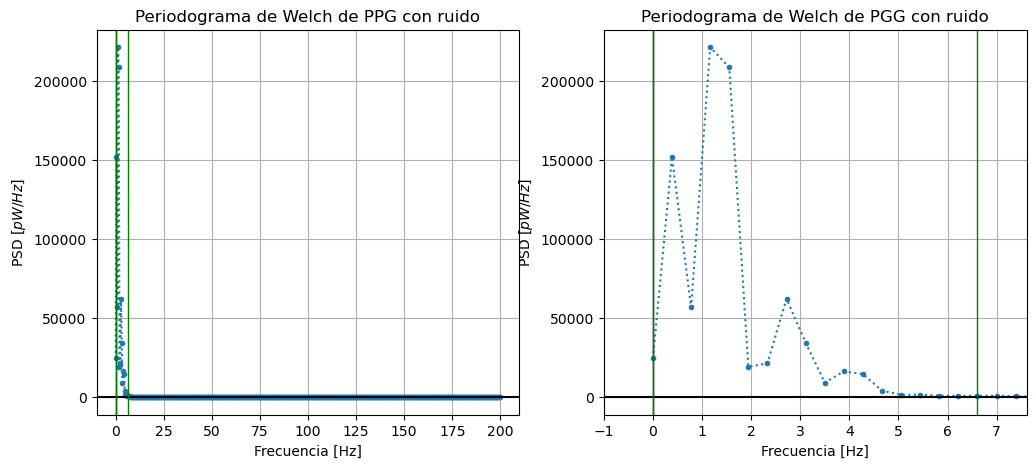

In [18]:
plt.figure(5, figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(freq,PSD,":.")
plt.grid()
plt.title("Periodograma de Welch de PPG con ruido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$pW/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

plt.subplot(1, 2, 2)
plt.plot(freq,PSD,":.")
plt.xlim([freq_low-1,freq_up+1])
plt.grid()
plt.title("Periodograma de Welch de PGG con ruido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$pW/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

Podemos apreciar como, efectivamente, tenemos picos muy notorios en aproximadamente 0.4 Hz, 1.2 Hz y 2.7 Hz, teniendo algunos picos menores en frecuencias adyacentes. Podemos ver como a pesar de la presencia de un ruido que a simple vista parecía modificar totalmente la señal, pudimos realizar un análisis de la PSD del PPG que pareciera ser bastante correcto. Para estar seguros, veamos que sucede en el caso sin ruido.

## Análisis PPG sin ruido

Nuevamente realizamos el procedimiento del caso anterior.

In [19]:
fs_ppg = 400

ppg = np.load('files/ppg_sin_ruido.npy')

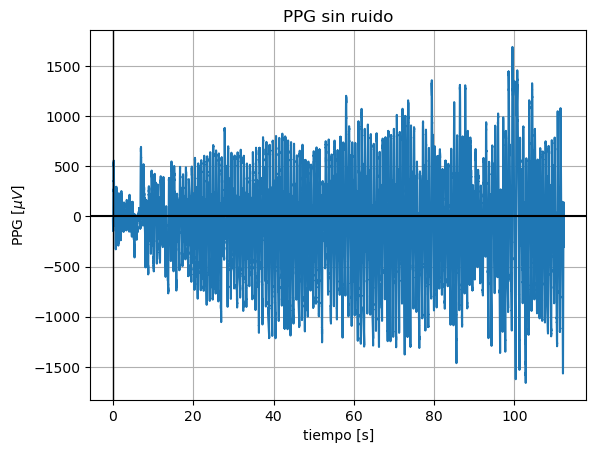

In [20]:
N = len(ppg)
t = np.arange(N)/fs_ppg

plt.figure(6)
plt.plot(t,ppg)
plt.grid()
plt.title("PPG sin ruido")
plt.xlabel("tiempo [s]")
plt.ylabel("PPG [$\mu V$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

Podemos apreciar como, efectivamente, si la señal no presenta una componente de ruido la misma debería oscilar al rededor del 0, lo cuál en en este caso esta sucediendo. Ahora veremos que consecuencias trae esto en la potencia y en el ancho de banda.

In [21]:
K = np.arange(30, 50, 2)
L = N // K

perio_welch_hann(ppg,fs_ppg,L)

K=30, Potencia=2.7e+05, sesgo (%)=-0.8972%
K=32, Potencia=2.7e+05, sesgo (%)=-1.5692%
K=34, Potencia=2.8e+05, sesgo (%)=-0.2258%
K=36, Potencia=2.8e+05, sesgo (%)=-0.6270%
K=38, Potencia=2.8e+05, sesgo (%)=-0.2319%
K=40, Potencia=2.8e+05, sesgo (%)=0.0649%
K=42, Potencia=2.7e+05, sesgo (%)=-1.4110%
K=44, Potencia=2.8e+05, sesgo (%)=0.3028%
K=46, Potencia=2.8e+05, sesgo (%)=-0.0790%
K=48, Potencia=2.8e+05, sesgo (%)=-0.0964%


La potencia estimada ahora es de aproximadamente 0.28 $\mu$W, es decir un 0.16% de lo que teníamos antes, demostrando una muy baja SNR. Veamos que sucede con el ancho de banda:

In [22]:
K=46
L = N//K

freq, PSD = sig.welch(ppg,fs_ppg,"hann",L)

freq_low, freq_up = band_width(PSD,freq)

frecuencia inferior:0.0 Hz, Frecuencia Superior: 6.967213114754099, Ancho de banda: 6.967213114754099


En este caso el ancho de banda aumento, seguramente como consecuencia de que al eliminar el ruido disminuyo la potencia en frecuencias cercanas a 0 Hz, sin embargo sigue siendo un valor razonable con el ancho de banda de la PPG, aunque esté casi 2 Hz por arriba. Veamos lo que dice el gráfico.

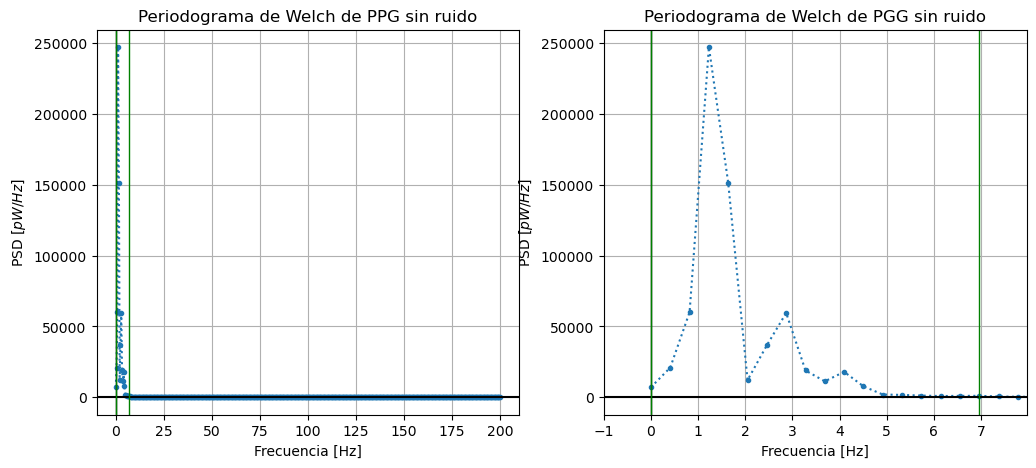

In [23]:
plt.figure(7, figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(freq,PSD,":.")
plt.grid()
plt.title("Periodograma de Welch de PPG sin ruido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$pW/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

plt.subplot(1, 2, 2)
plt.plot(freq,PSD,":.")
plt.xlim([freq_low-1,freq_up+1])
plt.grid()
plt.title("Periodograma de Welch de PGG sin ruido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$pW/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

Efectivamente, el pico que antes se apreciaba en 0.4 Hz ya no se encuentra presente, mientras que el de 1.2 y 2.7 continua ahí. Podemos ver como a pesar de que el ancho de banda obtenido es de 6.96 Hz, no se ven componentes fuertes a partir de los 5 Hz. Por lo cuál en este caso estimar el ancho de banda como el 99% quizás no es lo mas adecuado, puesto que visualmente si vemos el ancho de 5 Hz que esperaríamos teóricamente.

## Análisis sonido de prueba

A partir de este punto analizaremos lo que sucede con audios grabados por el profesor. En este caso, el audio dice "Esta es una prueba para la práctica de estimación espectral". Comenzamos este análisis leyendo la información del archivo de audio .wav y graficandolo en función al tiempo. Es importante aclarar que la unidad del gráfico en verdad es de amplitud digital normalizada, una unidad utilizada en archivos WAV que va de -1 a 1 en un rango normalizado. Sin embargo con finalidad de simplificación asumiremos que esta escala de normalización se la realiza entre 1V y -1V con un conversor posterior.

In [24]:
fs_prueba, wav_prueba = sio.wavfile.read('files/prueba psd.wav')

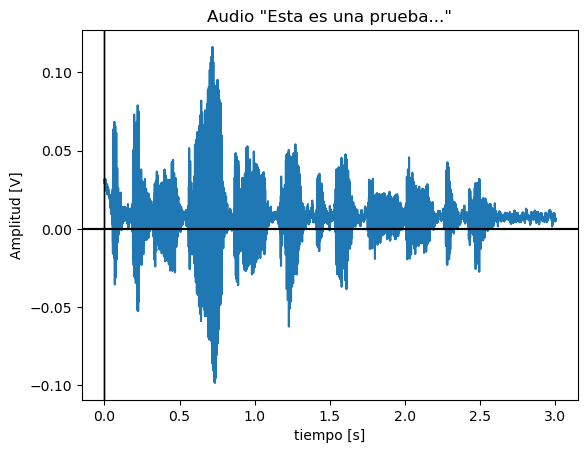

In [25]:
N = len(wav_prueba)
t = np.arange(N)/fs_prueba

plt.figure(8)
plt.plot(t,wav_prueba)
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.title('Audio "Esta es una prueba..."')
plt.xlabel("tiempo [s]")
plt.ylabel("Amplitud [V]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

Podemos apreciar el comportamiento normal esperado de una señal de voz, picos mas bajos y mas alto dependiendo del tono utilizado para hablar, aunque presenta un pequeño offset en relación al cero. Esto podría deberse tanto a ruido como a un verdadero valor de offset por el programa de grabación de voz. Procedemos a calcular su PSD mediante el Welch.

In [26]:
K = np.arange(30, 50, 2)
L = N // K

perio_welch_hann(wav_prueba,fs_prueba,L)

K=30, Potencia=0.00023, sesgo (%)=-2.9971%
K=32, Potencia=0.00023, sesgo (%)=-2.2983%
K=34, Potencia=0.00023, sesgo (%)=-0.3264%
K=36, Potencia=0.00023, sesgo (%)=-2.2980%
K=38, Potencia=0.00023, sesgo (%)=-0.8962%
K=40, Potencia=0.00023, sesgo (%)=-0.6485%
K=42, Potencia=0.00023, sesgo (%)=-0.8497%
K=44, Potencia=0.00023, sesgo (%)=-1.5058%
K=46, Potencia=0.00023, sesgo (%)=-0.7398%
K=48, Potencia=0.00023, sesgo (%)=-0.3948%


Nos encontramos con una potencia estimada de 0.23 mW. Veamos ahora que sucede con el ancho de banda.

In [27]:
K=34
L = N//K

freq, PSD = sig.welch(wav_prueba,fs_prueba,"hann",L)

freq_low, freq_up = band_width(PSD,freq)

frecuencia inferior:11.334120425029516 Hz, Frecuencia Superior: 3887.603305785124, Ancho de banda: 3876.2691853600945


En telefonía tradicionalmente se utilizaba un ancho de banda de 3.4 kHz, aunque actualmente se utiliza anchos de banda mayores de hasta 8 kHz. Si nos quedamos con este primer valor, el cuál seguramente es más lógico para un audio grabado, nuestro ancho de banda estimado se encuentra en un valor aceptable de 3.9 kHz. Ahora bien, será mas interesante ver los tonos donde se aprecia una mayor densidad espectral de potencia. Para eso realizamos los gráficos.

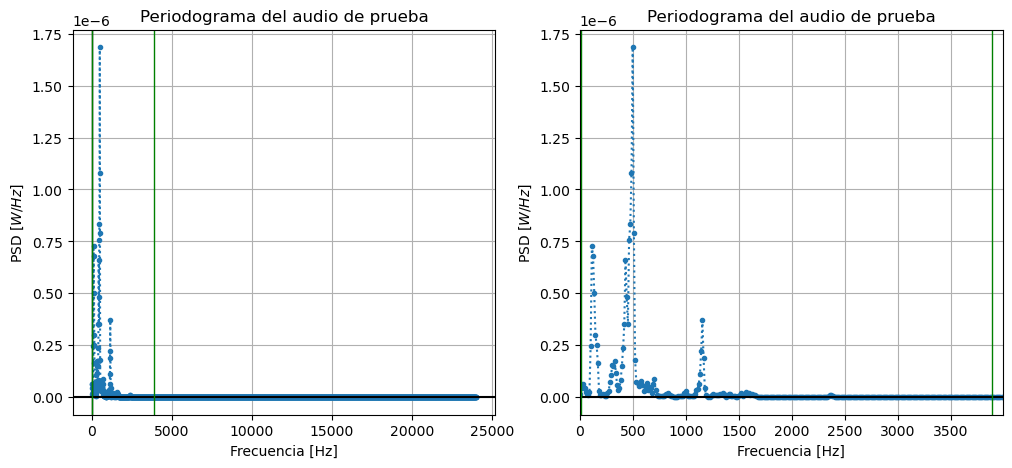

In [28]:
plt.figure(9, figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(freq,PSD,":.")
plt.grid()
plt.title("Periodograma del audio de prueba")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$W/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

plt.subplot(1, 2, 2)
plt.plot(freq,PSD,":.")
plt.xlim([0,freq_up+100])
plt.grid()
plt.title("Periodograma del audio de prueba")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$W/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

Podemos notar la existencia de 3 tonos fuertes en específico. Estos son aproximadamente 499 Hz, 113 Hz y 1156 Hz en orden de intensidad. Lo mas probable es que el tono de 113 Hz sea la frecuencia fundamental de la voz, la cual corresponde a una voz masculina adulta o a un tono grave de conversación relajada, justamente el tipo de voz que se escucha en el audio. Sin embargo, como Welch recorta el audio en pedazos mas chicos y promedia todo, es posible que no sea la mejor manera de estimar la frecuencia de una voz debido a la mezcla de distintos tonos, vocales y consonantes.

## Análisis silbido

Como sexto análisis veremos lo que sucede con un silbido de tonalidad aguda. Procedemos a extraer la información y realizar la figura.

In [29]:
fs_silbido, wav_silbido = sio.wavfile.read('files/silbido.wav')

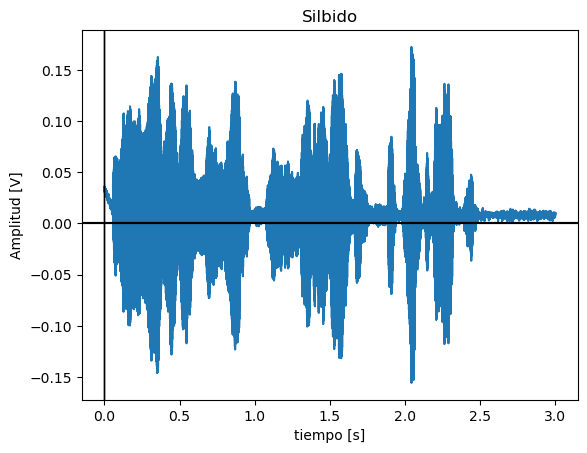

In [30]:
N = len(wav_silbido)
t = np.arange(N)/fs_silbido

plt.figure(10)
plt.plot(t,wav_silbido)
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.title('Silbido')
plt.xlabel("tiempo [s]")
plt.ylabel("Amplitud [V]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

Nos encontramos con un gráfico similar al caso anterior, aunque llegando a amplitudes mas altas. Esto posiblemente tenga relación con la mención de que estos silbidos son bastante agudos además de ser un sonido mas fuerte que el anterior. Continuamos con la realización del PSD.

In [31]:
K = np.arange(30, 50, 2)
L = N // K

perio_welch_hann(wav_silbido,fs_silbido,L)

K=30, Potencia=0.0016, sesgo (%)=2.1823%
K=32, Potencia=0.0016, sesgo (%)=0.7167%
K=34, Potencia=0.0016, sesgo (%)=2.8489%
K=36, Potencia=0.0016, sesgo (%)=0.0285%
K=38, Potencia=0.0016, sesgo (%)=2.5382%
K=40, Potencia=0.0016, sesgo (%)=1.5076%
K=42, Potencia=0.0016, sesgo (%)=0.9958%
K=44, Potencia=0.0016, sesgo (%)=1.5915%
K=46, Potencia=0.0016, sesgo (%)=1.1217%
K=48, Potencia=0.0016, sesgo (%)=0.4665%


Estimamos una potencia de 1.6 mW. Esta potencia es mayor a la del audio anterior, lo cuál no tiene relación con el tono del audio si no con que el de prueba era una frase dicha con una voz moderada. Sin embargo este silbido tiene una mayor intensidad que se siente al escucharla y se puede ver, justamente, en la amplitud de los picos. Veamos que sucede con el ancho de banda.

In [32]:
K=36
L = N//K

freq, PSD = sig.welch(wav_silbido,fs_silbido,"hann",L)

freq_low, freq_up = band_width(PSD,freq)

frecuencia inferior:2628.0 Hz, Frecuencia Superior: 6696.0, Ancho de banda: 4068.0


Podemos ver que este es el primer caso donde la frecuencia inferior se encuentra alejada de los 0 Hz. Además, si bien el ancho de banda es de 4068 Hz, la frecuencia máxima es de 6696 Hz. El silbido humano suele estar entre los 1kHz y 2.5kHz, sin embargo estos valores no son tan agudos como el audio real que se escucha. Se considere que silbidos más agudos pueden llegar a encontrarse entre los 4 kHz y 10 kHz, lo que en este caso tiene mas sentido. Nuevamente, comprobamos gráficamente.

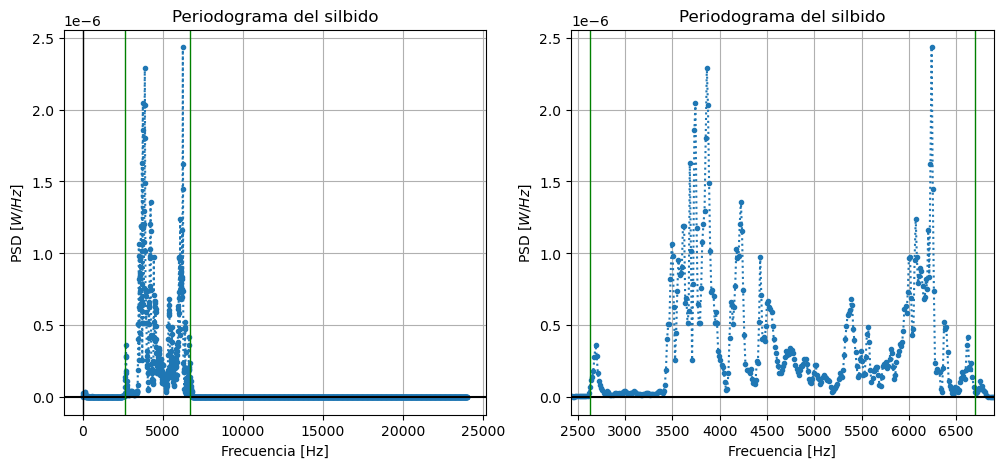

In [33]:
plt.figure(11, figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(freq,PSD,":.")
plt.grid()
plt.title("Periodograma del silbido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$W/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

plt.subplot(1, 2, 2)
plt.plot(freq,PSD,":.")
plt.xlim([freq_low-200,freq_up+200])
plt.grid()
plt.title("Periodograma del silbido")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$W/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

Notamos la presencia de una gran variedad de tonos difíciles de identificar, lo cuál nos habla de un silbido el cual varía su tonalidad a lo largo del audio de manera indiscriminada, que es en cierta manera lo que sucede en el audio, por lo cual no existe algún posible análisis mas específico.

## Análisis silbido de "La Cucaracha"

Por último analizaremos un audio donde se silba la melodía de la popular canción "La Cucaracha".

In [34]:
fs_cucaracha, cucaracha_data = sio.wavfile.read('files/la cucaracha.wav')

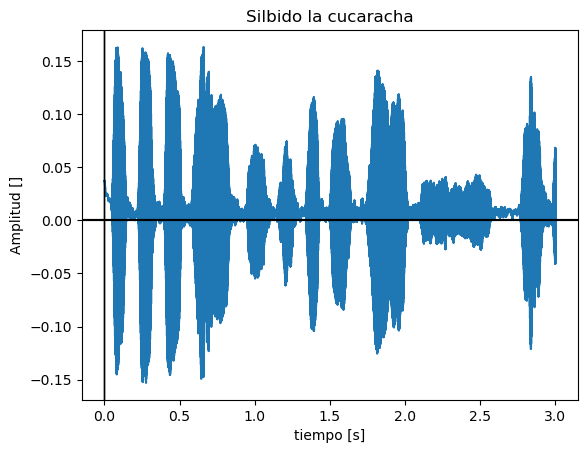

In [35]:
N = len(cucaracha_data)
t = np.arange(N)/fs_cucaracha

plt.figure(12)
plt.plot(t,cucaracha_data)
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.title('Silbido la cucaracha')
plt.xlabel("tiempo [s]")
plt.ylabel("Amplitud []")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

En el gráfico podemos apreciar hasta el segundo 2.25 algo similar a la parte de "Tu-Tu-Tu-Tuuuu-Tu" que corresponde a "La-Cu-Ca-Raaaa-Cha" repetido dos veces. Esto en una entonación clásica de la canción corresponde a tonos de 261.63 Hz, 349.23 Hz y 440.0 Hz. Por lo cuál, suponiendo una correcta afinación, esperaríamos que los tonos hallados en la PSD sean armónicos de estas frecuencias. 

In [36]:
K = np.arange(30, 50, 2)
L = N // K

perio_welch_hann(cucaracha_data,fs_cucaracha,L)

K=30, Potencia=0.0019, sesgo (%)=1.4091%
K=32, Potencia=0.0019, sesgo (%)=0.5396%
K=34, Potencia=0.0019, sesgo (%)=1.8323%
K=36, Potencia=0.0019, sesgo (%)=1.8381%
K=38, Potencia=0.0019, sesgo (%)=1.1797%
K=40, Potencia=0.0019, sesgo (%)=0.5062%
K=42, Potencia=0.0019, sesgo (%)=0.7162%
K=44, Potencia=0.0019, sesgo (%)=0.3286%
K=46, Potencia=0.0019, sesgo (%)=1.9830%
K=48, Potencia=0.0019, sesgo (%)=0.7942%


Tenemos una potencia de 1.9 mW, lo cuál nos muestra que se encuentra en un nivel de intensidad similar al silvido previo pero mas leve, lo cuál escuchando el audio es evidentemente cierto. Analizemos su ancho de banda.

In [37]:
K=44
L = N//K

freq, PSD = sig.welch(cucaracha_data,fs_cucaracha,"hann",L)

freq_low, freq_up = band_width(PSD,freq)

frecuencia inferior:982.885085574572 Hz, Frecuencia Superior: 2024.4498777506112, Ancho de banda: 1041.5647921760392


Vemos que la potencia se distribuye principalmente entre frecuencias de 982.88 Hz y 2.024 kHz, lo cuál se asemeja más al ancho de banda previamente comentado para silbidos humanos. Esto se da debido a que justamente este audio suena mas como la entonación de una canción mientras que el otro audio eran silbidos mucho mas agudos. Veamos que podemos observar en el gráfico. 

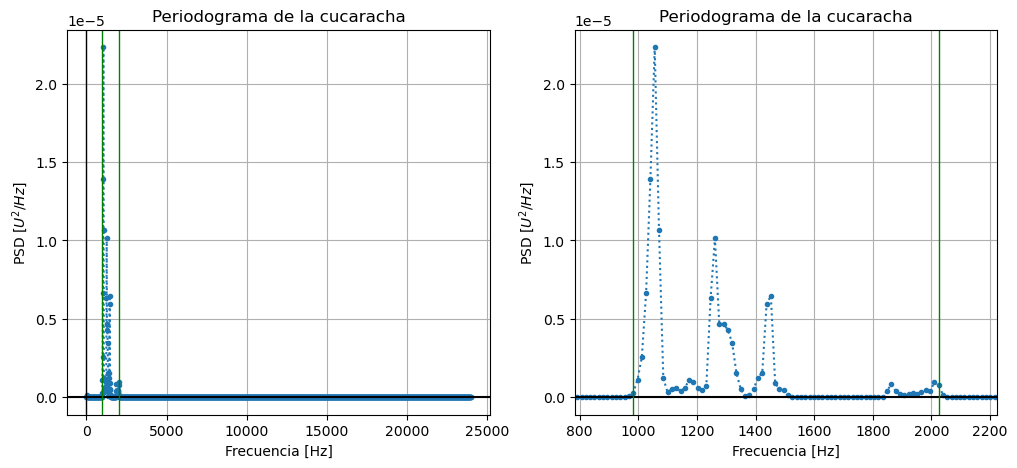

In [38]:
plt.figure(13, figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(freq,PSD,":.")
plt.grid()
plt.title("Periodograma de la cucaracha")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$U^2/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

plt.subplot(1, 2, 2)
plt.plot(freq,PSD,":.")
plt.xlim([freq_low-200,freq_up+200])
plt.grid()
plt.title("Periodograma de la cucaracha")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [$U^2/Hz$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

Nos encontramos con tres tonos bastante notorios, que se encuentran a frecuencias de 1056 Hz, 1262 Hz y 1452 Hz. Justamente habíamos mencionado que la canción cuenta de tres notas distintas, además que al no ser múltiplos entre sí queda descartada la idea de que sean armónicos de la misma nota. Por lo cuál un análisis interesante sería ver si estas frecuencias son múltiplos de las notas previamente mencionadas. Vemos que:
\begin{equation}
\frac{1056 Hz}{261.63 Hz} \approx 4.04
\end{equation}
\begin{equation}
\frac{1262 Hz}{349.23 Hz} \approx 3.61
\end{equation}
\begin{equation}
\frac{1452 Hz}{440.0 Hz} \approx 3.3
\end{equation}
Al no ser múltiplos enteros de la frecuencia esperada, lo mas probable es que efectivamente sean estas notas solo que entonadas de manera desafinada, lo cuál es lógico considerando que estamos analizando un silbido.

Como último análisis nos parecía interesante ver que tan diferente es hacer el periodograma de Welch frente a la FFT común que veníamos haciendo. Esto debido a que conocemos que para procesos estocásticos es muy útil porque disminuye la varianza, pero que tanto afecta esto en las señales analizadas es algo que no tenemos tanta precisión. Para eso, procedemos a graficar la FFT normal.

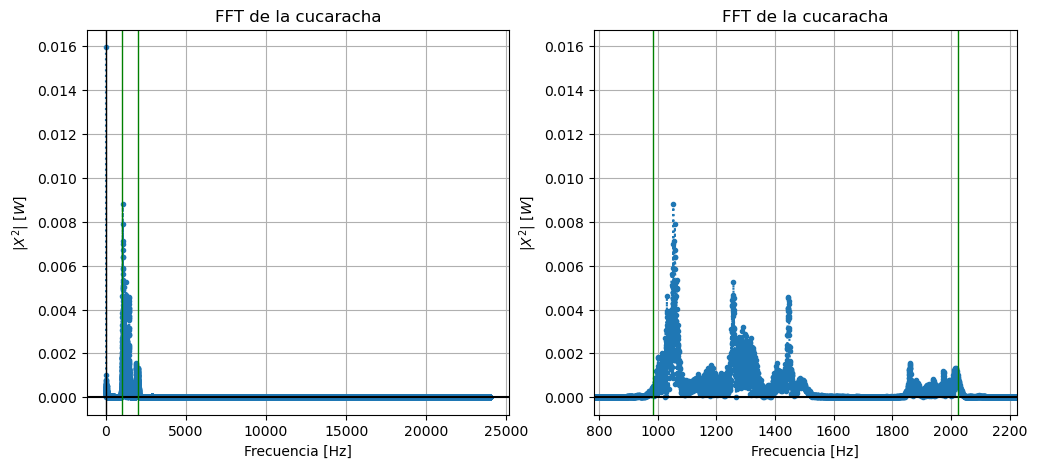

In [39]:
fftxx = fft(cucaracha_data)[:N//2]/N * 2
freq = fftfreq(N,1/fs_cucaracha)[:N//2]
fftxx_abs = np.abs(fftxx)

plt.figure(14, figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(freq,fftxx_abs,":.")
plt.grid()
plt.title("FFT de la cucaracha")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("|$X^2$| [$W$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

plt.subplot(1, 2, 2)
plt.plot(freq,fftxx_abs,":.")
plt.xlim([freq_low-200,freq_up+200])
plt.grid()
plt.title("FFT de la cucaracha")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("|$X^2$| [$W$]")
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)
plt.axvline(freq_low,color="green",linewidth=1)
plt.axvline(freq_up,color="green",linewidth=1)

Podemos ver como se vuelve mas difícil apreciar los armónicos previamente mencionados, ya que ahora el gráfico presenta un desparramo espectral mucho mas visible. Además, aparecen nuevas componentes muy fuertes tanto alrededor de los 0 Hz y al final del ancho de banda del periodograma, aproximadamente entre 1800 Hz y 2000 Hz. Esto nos muestra porque el periodograma de Welch es un mejor estimador.

## Cuadro de los BW
| Señal | Frecuencia inferior | Frecuencia superior | Ancho de Banda | Ancho de Banda de referencia | 
|---|---:|---:|---:|---:|
| ECG con ruido | 0.0 Hz | 31.5 Hz | 31.5 Hz | 35.0 Hz |
| ECG sin ruido | 0.0 Hz | 35.8 Hz | 35.8 Hz | 35.0 Hz |
| PPG con ruido | 0.0 Hz | 6.61 Hz | 6.61 Hz | 5.0 Hz |
| PPG sin ruido | 0.0 Hz | 6.97 Hz | 6.97 Hz | 5.0 Hz |
| Audio Prueba | 11.33 Hz | 3887.6 Hz | 3876.27 Hz | 3400 Hz |
| Silbido Agudo | 2628.0 Hz | 6696 Hz | 4068 Hz | 9000 Hz (1 kHz - 10 kHz) |
| La cucaracha | 982.89 Hz | 2024.45 Hz | 1041.56 Hz | ? Hz |

Podemos apreciar como, especialmente para las señales sin ruido, nuestro estimador del ancho de banda fue bastante preciso, acercándose al valor esperado (sesgo bajo). Hablar de su varianza en este caso no tiene mucho sentido debido a que solo tenemos una realización en cada caso, por lo cuál es un análisis que queda pendiente aunque seguramente tenga mucha relación con la varianza del periodograma de Welch en sí. Es importante destacar que en la mayoría de los casos nuestro ancho de banda fue mayor al teórico, por lo cuál probablemente establecer 99% fue una medida muy agresiva y con otro porcentaje, por ejemplo 95%, se hubiera acercado más.

# Conclusión

A lo largo de este trabajo hemos logrado realizar distintas conclusiones al respecto de la utilización del método de Welch y de la estimación del ancho de banda de las señales.

Como primer conclusión pudimos ver como la presencia de una señal de ruido y/o de una componente de continua influencia en gran medida al periodograma. Esto se aprecia especialmente en los casos de PPG y ECG con y sin ruido. Por esto fue importante aprovechar dos configuraciones distintas de la función de sig.welch, el detrend. Una de ellas permitía conservar esta componente continua para poder realizar una estimación de la potencia total, y otra que la elimina para poder estima el ancho de banda.

Por el lado del ancho de banda, adoptamos el criterio de que este era el intervalo de frecuencias entre los cuales se distribuía el intervalo de potencias entre el 0.5% y el 99.5% de la potencia espectral acumulada. Esto permitió poder aplicar el mismo criterio a señales muy distintas, algo que el criterio de -3dB no nos hubiera permitido. Los resultados obtenidos fueron razonables y compatibles con lo esperado, aunque observamos que la elección del porcentaje pudo haber sido distinta y dar mejores resultados.

Por último, comprobamos que la elección de los parámetros de Welch implica consecuencias en la resolución espectral y la cantidad de segmentos disponibles para promediar (en cierta forma, la varianza). Esto conlleva a que mejorar una, empeore la otra, y viceversa. Evidenciamos como modificar la longitud de los segmenos cambiaba la estimación de la potencia, lo que demuestra la importancia de seleccionar parámetros adecuados para cada caso.